# Instagram Engagement Prediction Using Machine Learning
**Course:** Predictive Analysis  
**Approach:** Supervised Learning – Regression  
**Algorithm:** Random Forest Regressor  

> **Dataset note:** This project uses a synthetic/demo dataset generated for coursework. It is not actual Instagram Insights data and results should not be interpreted as real-world performance guarantees.


## 1. Problem Statement
Predict the number of likes on an Instagram post using available post details such as follower count, content type, posting time, day of week, hashtag count and Reel duration.

## 2. Objectives
- Explore and visualize post-performance data.
- Prepare input features for machine learning.
- Train a Random Forest Regression model.
- Evaluate predictions using MAE, RMSE and R².
- Predict likes for a new example post.


## 3. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme()


## 4. Load Dataset

In [11]:
df = pd.read_csv("instagram_engagement_synthetic.csv")
print("Dataset shape:", df.shape)
display(df.head())
print(df.info())


Dataset shape: (500, 11)


,followers,post_type,posting_hour,day_of_week,hashtag_count,reel_duration_sec,likes,comments,saves,shares,engagement_rate
0,4917,Photo,15,Sunday,11,0,408,17,10,6,8.97
1,38810,Carousel,10,Monday,1,0,1874,78,71,70,5.39
2,32901,Reel,10,Wednesday,12,84,2753,99,33,36,8.88
3,22224,Reel,11,Thursday,1,87,1976,81,27,78,9.73
4,21934,Reel,16,Saturday,0,65,2129,110,95,39,10.82


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   followers          500 non-null    int64  
 1   post_type          500 non-null    object 
 2   posting_hour       500 non-null    int64  
 3   day_of_week        500 non-null    object 
 4   hashtag_count      500 non-null    int64  
 5   reel_duration_sec  500 non-null    int64  
 6   likes              500 non-null    int64  
 7   comments           500 non-null    int64  
 8   saves              500 non-null    int64  
 9   shares             500 non-null    int64  
 10  engagement_rate    500 non-null    float64
dtypes: float64(1), int64(8), object(2)
memory usage: 43.1+ KB
None


## 5. Exploratory Data Analysis

In [3]:
print(df.describe(include="all"))
print("\\nMissing values:\\n", df.isnull().sum())


         followers post_type  posting_hour day_of_week  hashtag_count  \
count     500.0000       500    500.000000         500     500.000000   
unique         NaN         3           NaN           7            NaN   
top            NaN      Reel           NaN   Wednesday            NaN   
freq           NaN       271           NaN          88            NaN   
mean    25208.8960       NaN     14.224000         NaN       7.740000   
std     14153.4717       NaN      5.262434         NaN       4.678052   
min       762.0000       NaN      6.000000         NaN       0.000000   
25%     13474.7500       NaN     10.000000         NaN       3.000000   
50%     24978.5000       NaN     14.000000         NaN       8.000000   
75%     37622.0000       NaN     19.000000         NaN      12.000000   
max     49902.0000       NaN     23.000000         NaN      15.000000   

        reel_duration_sec        likes    comments       saves      shares  \
count          500.000000   500.000000  500.0

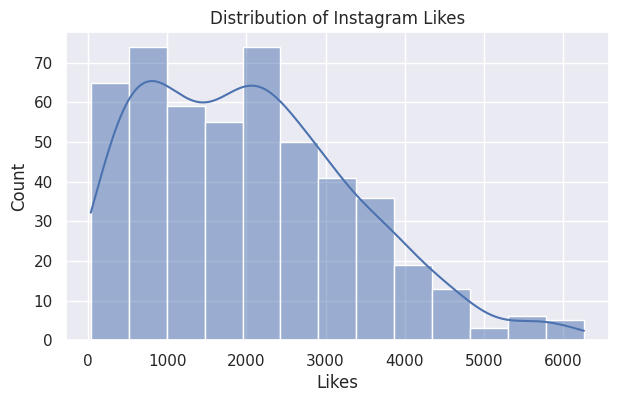

In [4]:
plt.figure(figsize=(7,4))
sns.histplot(df["likes"], kde=True)
plt.title("Distribution of Instagram Likes")
plt.xlabel("Likes")
plt.show()


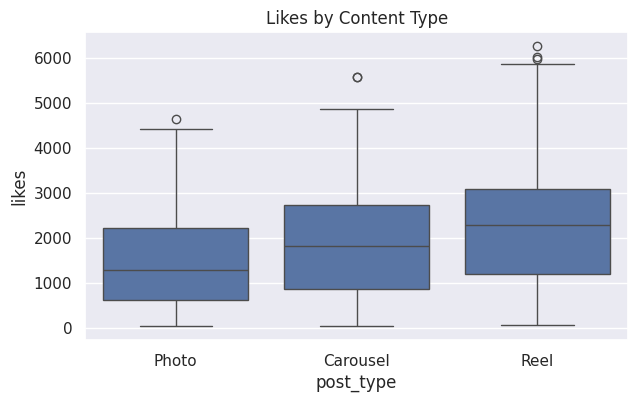

In [5]:
plt.figure(figsize=(7,4))
sns.boxplot(data=df, x="post_type", y="likes")
plt.title("Likes by Content Type")
plt.show()


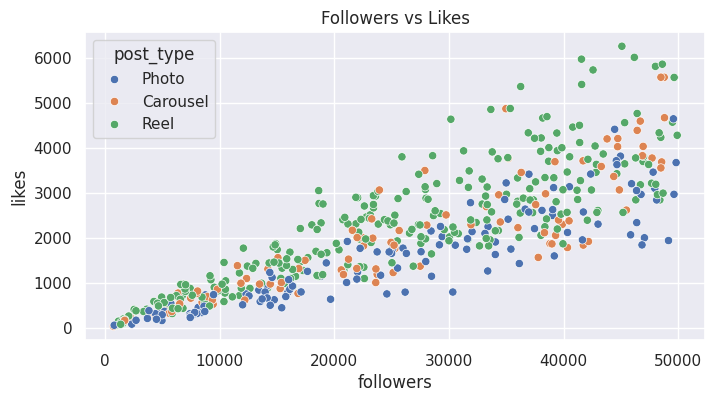

In [6]:
plt.figure(figsize=(8,4))
sns.scatterplot(data=df, x="followers", y="likes", hue="post_type")
plt.title("Followers vs Likes")
plt.show()


## 6. Data Preparation and Model Training
The target variable is `likes`. We exclude comments, saves, shares and engagement rate from the inputs because these are engagement outcomes and would cause target leakage when predicting likes.

In [7]:
target = "likes"
features = ["followers", "post_type", "posting_hour", "day_of_week",
            "hashtag_count", "reel_duration_sec"]

X = df[features]
y = df[target]

numeric_features = ["followers", "posting_hour", "hashtag_count", "reel_duration_sec"]
categorical_features = ["post_type", "day_of_week"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", SimpleImputer(strategy="median"), numeric_features),
        ("cat", Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]), categorical_features)
    ]
)

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(n_estimators=150, random_state=42))
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model.fit(X_train, y_train)
print("Model training completed.")


Model training completed.


## 7. Model Evaluation

In [8]:
predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print(f"MAE:  {mae:.2f} likes")
print(f"RMSE: {rmse:.2f} likes")
print(f"R² Score: {r2:.3f}")


MAE:  557.70 likes
RMSE: 772.63 likes
R² Score: 0.701


,Actual Likes,Predicted Likes
0,3717,3287
1,821,753
2,3367,3426
3,2696,2129
4,1870,3318
5,1431,2275
6,4217,3284
7,3461,3619
8,587,372
9,3193,3958


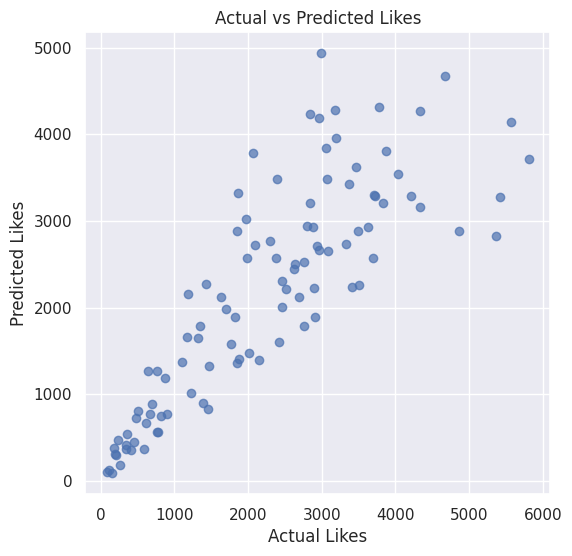

In [9]:
results = pd.DataFrame({"Actual Likes": y_test.values,
                         "Predicted Likes": np.round(predictions).astype(int)})
display(results.head(10))

plt.figure(figsize=(6,6))
plt.scatter(y_test, predictions, alpha=0.7)
plt.xlabel("Actual Likes")
plt.ylabel("Predicted Likes")
plt.title("Actual vs Predicted Likes")
plt.show()


## 8. Predict Engagement for a New Post

In [10]:
new_post = pd.DataFrame([{
    "followers": 12000,
    "post_type": "Reel",
    "posting_hour": 19,
    "day_of_week": "Saturday",
    "hashtag_count": 8,
    "reel_duration_sec": 30
}])

predicted_likes = model.predict(new_post)[0]
print(f"Estimated likes for the sample post: {predicted_likes:.0f}")


Estimated likes for the sample post: 967


## 9. Conclusion
A Random Forest Regression model was trained to estimate Instagram post likes from post characteristics. The model was evaluated on a held-out test set using MAE, RMSE and R². The notebook demonstrates the complete predictive analysis workflow: data loading, exploration, preprocessing, training, evaluation and prediction.

**Limitations:** The dataset is synthetic and designed only to demonstrate the method. Real Instagram performance depends on many additional factors, and this model should be retrained and evaluated on genuine, permissioned historical data before practical use.
